# 2. Model Training and Evaluation

# Model Training

This stage is used to train the model using the **train**, **test**, and **validation** datasets that have been annotated and labeled in **Roboflow**. <br>

The training process follows the standard **YOLOv26** workflow, including data augmentation, model optimization, and validation to evaluate performance.


In [1]:
"""!pip install ultralytics
!pip install torch torchvision
!pip install pillow
!pip install gdal
!pip install patchify
!pip install rasterio
!pip install shapely
!pip install fiona
!pip install tifffile
!pip install roboflow
!pip install numpy"""


'!pip install ultralytics\n!pip install torch torchvision\n!pip install pillow\n!pip install gdal\n!pip install patchify\n!pip install rasterio\n!pip install shapely\n!pip install fiona\n!pip install tifffile\n!pip install roboflow\n!pip install numpy'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Dataset
Import or download labeled datasets/images from **Roboflow**. You can either use the **API** integration or manually download the dataset and place the folder inside your project environment. <br>

The script below is generated automatically from the **Roboflow API**. <br>


In [3]:
"""from IPython.display import Image, display

display(Image("https://github.com/mwahyur46/oilpalm-tree-detection-yolov12/blob/main/images/dataset_import_api.jpg"))
"""

'from IPython.display import Image, display\n\ndisplay(Image("https://github.com/mwahyur46/oilpalm-tree-detection-yolov12/blob/main/images/dataset_import_api.jpg"))\n'

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="u3UIOc5ovdRCfiZLGubI")
project = rf.workspace("mwahyur").project("oilpalm-tree-detection-vllsd")
version = project.version(2)
dataset = version.download("yolo26")


After running the script above, a new folder will be created in the environment with a name corresponding to the project. <br>

In this case, the folder is named `Oil-palm-Tree-Detection-2`, where the suffix `-2` indicates the dataset version. <br>

If executed in **Google Colab**, a new folder will appear as shown in the following image.


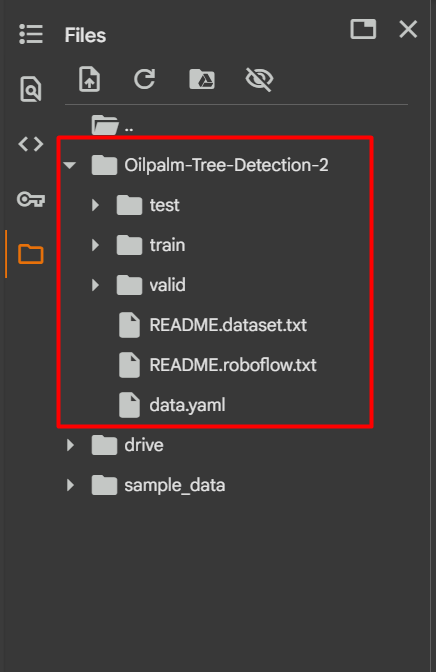

## Import YOLO Model

This step is used to load the **YOLOv26** model from **Ultralytics**. <br>

The model comes in several variations, each with different levels of complexity and performance.  
A more complex model generally requires higher computational resources. <br>

For this case study, this repository uses the **YOLO-N (Nano)** model, which is the smallest and most lightweight version. <br>

[**Official Documentation**](https://docs.ultralytics.com/models/yolo12/)


In [5]:
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {DEVICE}')

Using cuda


In [7]:
!pip install ultralytics
from ultralytics import YOLO

# Load YOLO model from Ultralytics
model = YOLO(r"/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/yolo26n.pt")  # load a pretrained model (recommended for training)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Model Training

Train the model using the dataset annotated in **Roboflow**.  
The parameters used are as follows: <br>

- `data` → Raster data with labels  
- `epoch` → Number of training iterations performed by the model  
- `imgsz` → Tile resolution of the raster data  
- `batch` → Number of samples in a single training iteration  
- `device` → Selects the GPU for training. If available, set to `0` for CUDA or `cpu` to use the CPU <br>

[**Official Documentation 1**](https://docs.ultralytics.com/modes/train/#key-features-of-train-mode)  
[**Official Documentation 2**](https://docs.ultralytics.com/modes/train/#train-settings)


**Note:** <br>
The `data.yaml` file contains directory paths for train, test, and label images. Open the file and adjust the paths according to your directory structure. Make sure the paths are written in full.  

Below is an example of a `data.yaml` file as shown in **Google Colab**. <br>
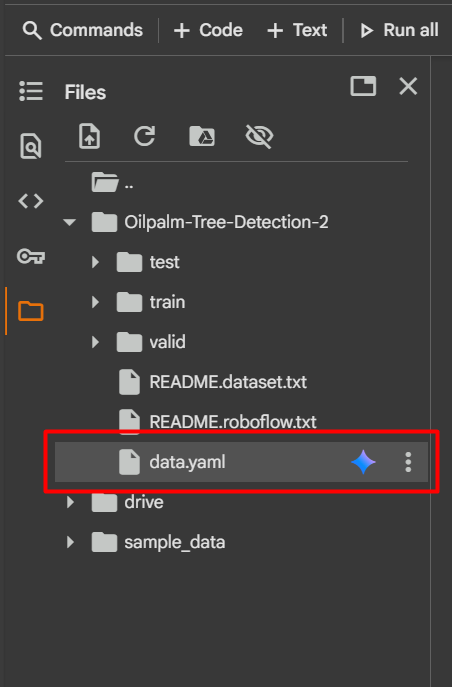


In [8]:
# Model Training
model.train(data=r'/content/Oilpalm-Tree-Detection-2/data.yaml', epochs=50, imgsz=640, batch=16, device=DEVICE)


Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Oilpalm-Tree-Detection-2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=Fals

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ceafa840740>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Save Model

Save the model after the training process is completed.

In [9]:
# Save Model
model_path = r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/oilpalm_detection_model_yolov26n.pt'
model.save(model_path)
print(f"Model Saved to {model_path}.")

Model Saved to /content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/oilpalm_detection_model_yolov26n.pt.


Check the saved model to ensure that it correctly displays the **oilpalm** class or the corresponding label defined in the Roboflow dataset.

In [10]:
from ultralytics import YOLO

# Load the trained model
model = YOLO(r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/oilpalm_detection_model_yolov26n.pt')

# Print the class labels
class_labels = model.names
print("Class Labels:", class_labels)

Class Labels: {0: 'oilpalm'}


# Model Performance Evaluation

## Standard YOLO Validation

Before performing the custom IoU-based evaluation below, run the standard validation routine provided by **Ultralytics**. This produces the conventional YOLO benchmarking metrics: **mAP50** and **mAP50-95** (averaged across IoU thresholds 0.5 to 0.95). It also automatically generates a **confusion matrix**, **PR curve**, and **F1 curve**, all saved under `runs/detect/val/`.

In [11]:
# Run the standard YOLO validation on the validation split
metrics = model.val(data=r'/content/Oilpalm-Tree-Detection-2/data.yaml')

# Print headline metrics
print(f"mAP50      : {metrics.box.map50:.4f}")
print(f"mAP50-95   : {metrics.box.map:.4f}")
print(f"Precision  : {metrics.box.mp:.4f}")
print(f"Recall     : {metrics.box.mr:.4f}")

Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2665.1±1192.6 MB/s, size: 93.5 KB)
val: Scanning /content/Oilpalm-Tree-Detection-2/valid/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 3.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.3it/s 0.3s
                   all         10        256      0.856      0.891      0.941      0.586
Speed: 0.8ms preprocess, 14.7ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /content/runs/detect/val
mAP50      : 0.9407
mAP50-95   : 0.5861
Precision  : 0.8564
Recall     : 0.8906


This script evaluates the trained **YOLOv26** model on the validation dataset.<br>

Key Metrics
- **IoU (Intersection over Union)**: Measures the overlap between predicted and ground truth bounding boxes (threshold: 0.5).  
- **True Positives (TP)**: Correct detections with IoU > 0.5.  
- **False Positives (FP)**: Incorrect detections or IoU < 0.5.  
- **False Negatives (FN)**: Missed ground truth objects.  
- **Precision**: `TP / (TP + FP)` — measures detection accuracy.  
- **Recall**: `TP / (TP + FN)` — measures coverage of ground truth objects.  
- **F1-Score**: Harmonic mean of Precision and Recall.  
- **Average Precision (AP)**: Area under the Precision-Recall curve. <br>

Output
- Side-by-side visualization (**Original vs Detection**)  
- Per-image statistics (TP, FP, FN counts)  
- Overall metrics (Precision, Recall, F1-Score, AP)  
- Precision-Recall curve<br>  

Use the test data located in the `test/images` folder. <br>

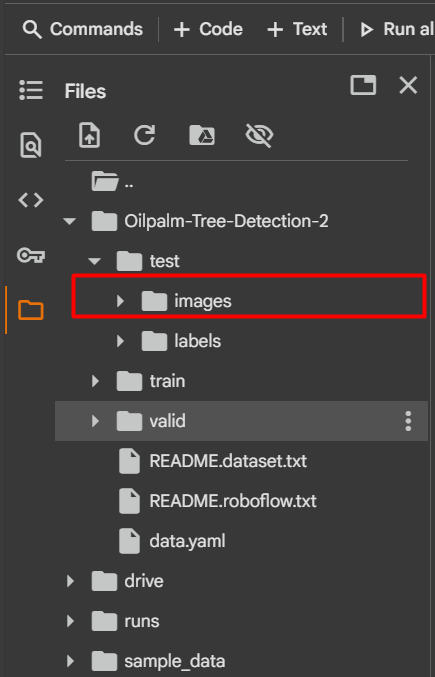

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO
from sklearn.metrics import precision_recall_curve, average_precision_score


In [13]:
# Load the trained model
model = YOLO(r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/oilpalm_detection_model_yolov26n.pt')
print(f"Model loaded successfully. Device: {model.device}")

# Path to the validation images folder
validation_images_folder = r'/content/Oilpalm-Tree-Detection-2/valid/images'

# Get list of all images in the validation folder
validation_images = [
    os.path.join(validation_images_folder, img)
    for img in os.listdir(validation_images_folder)
    if img.endswith(('.png', '.jpg', '.jpeg', '.tif'))
]

print(f"Found {len(validation_images)} validation images\n")



Model loaded successfully. Device: cpu
Found 10 validation images



Processing image 1/10: 45_png.rf.5f3c5a193d267fcaf3312012980ee799.jpg


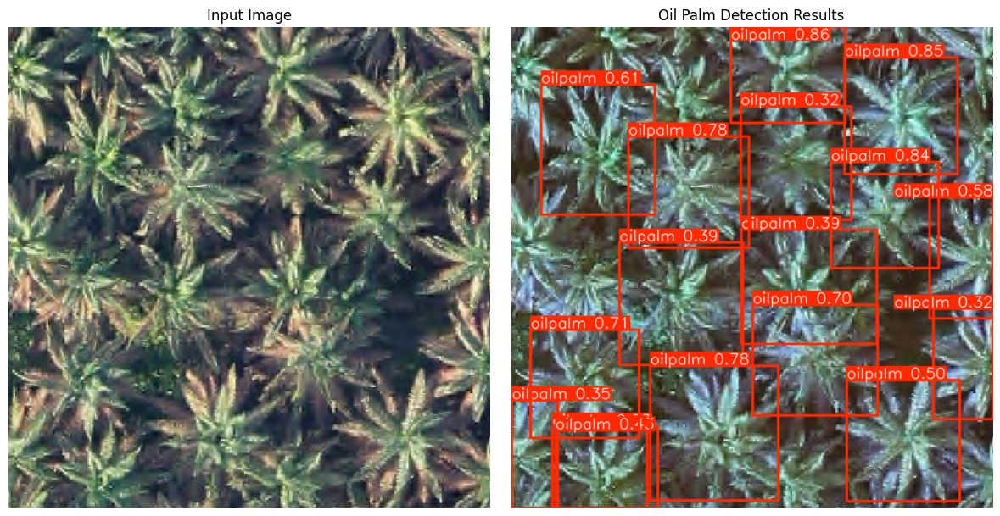

Ground Truth: 14 | Detected: 17 | TP: 13 | FP: 4 | FN: 1
----------------------------------------------------------------------

Processing image 2/10: 10_png.rf.fb87dfe1fb89580eb912aded8980772d.jpg


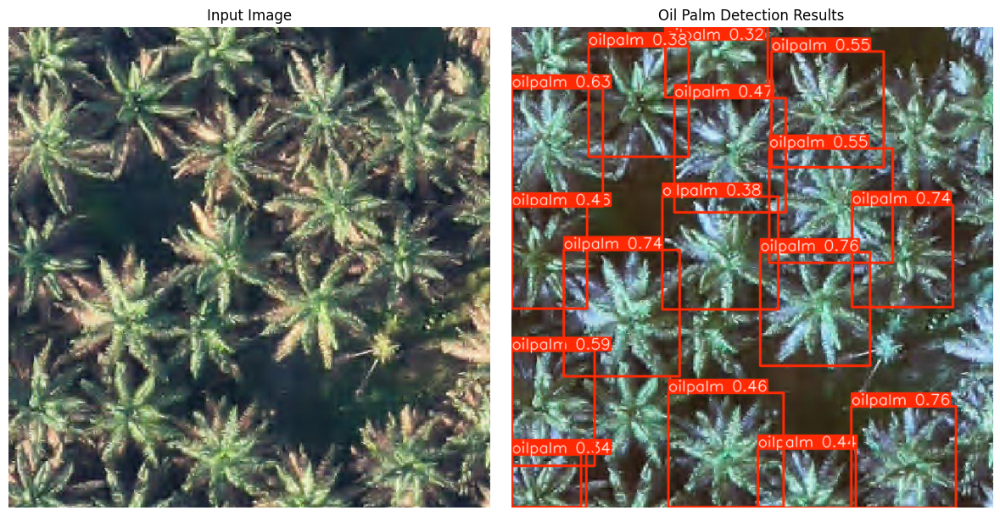

Ground Truth: 17 | Detected: 17 | TP: 14 | FP: 3 | FN: 3
----------------------------------------------------------------------

Processing image 3/10: 125_png.rf.5fd46422566a4eb86bf3f70172e92977.jpg


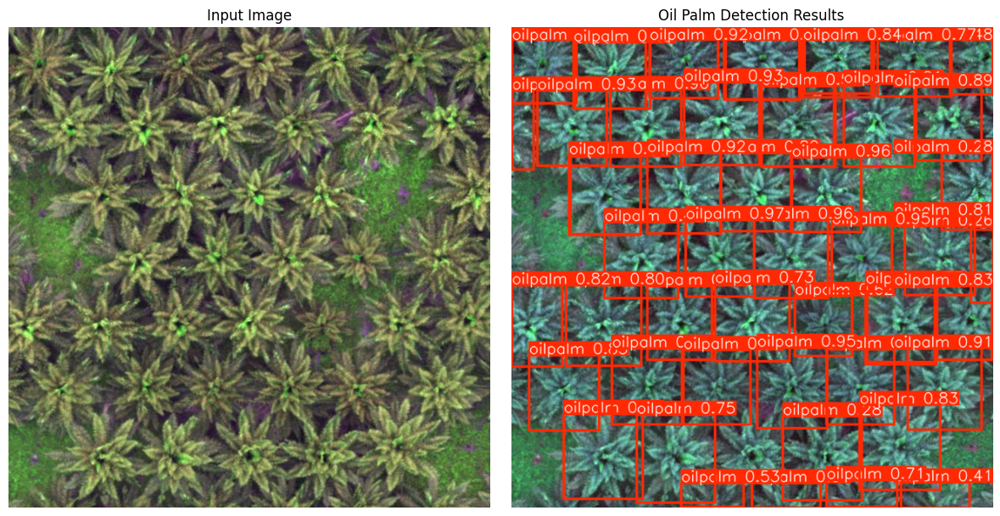

Ground Truth: 39 | Detected: 53 | TP: 45 | FP: 8 | FN: -6
----------------------------------------------------------------------

Processing image 4/10: 10_png.rf.89f1d87a70149d632bf86b354b1ca43c.jpg


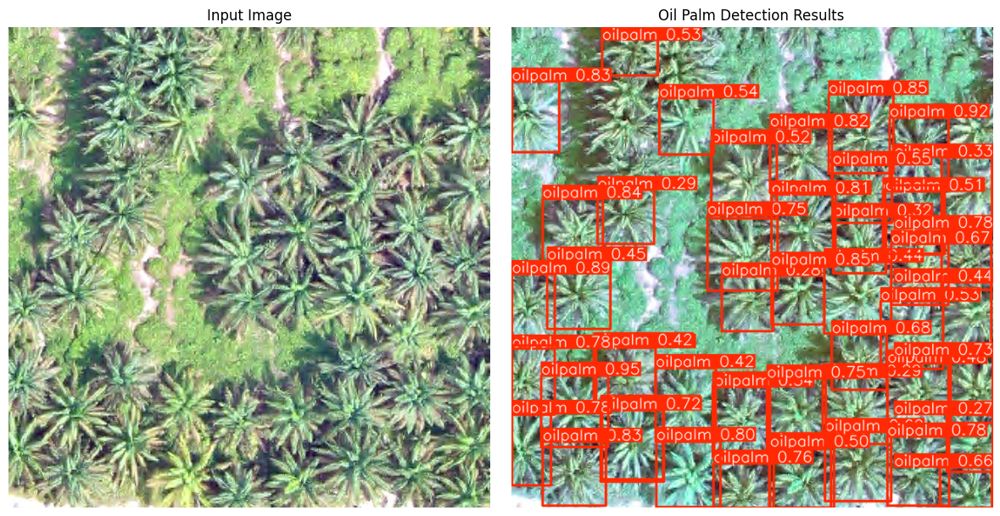

Ground Truth: 41 | Detected: 49 | TP: 40 | FP: 9 | FN: 1
----------------------------------------------------------------------

Processing image 5/10: 143_png.rf.69c6dc3a8bbbf69d4fb798833ff8eb8d.jpg


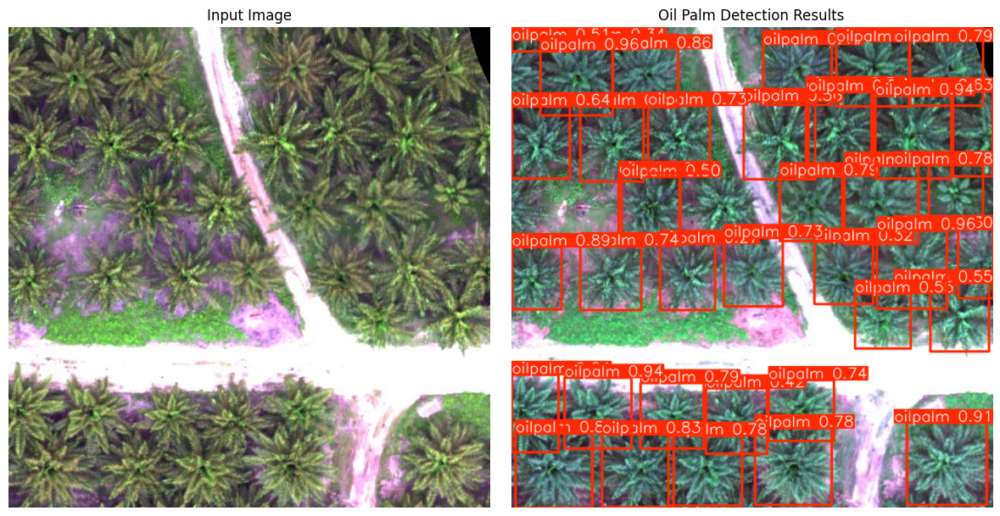

Ground Truth: 34 | Detected: 39 | TP: 35 | FP: 4 | FN: -1
----------------------------------------------------------------------

Processing image 6/10: 16_png.rf.f062b212f8aaf997ab57ec84bc63242c.jpg


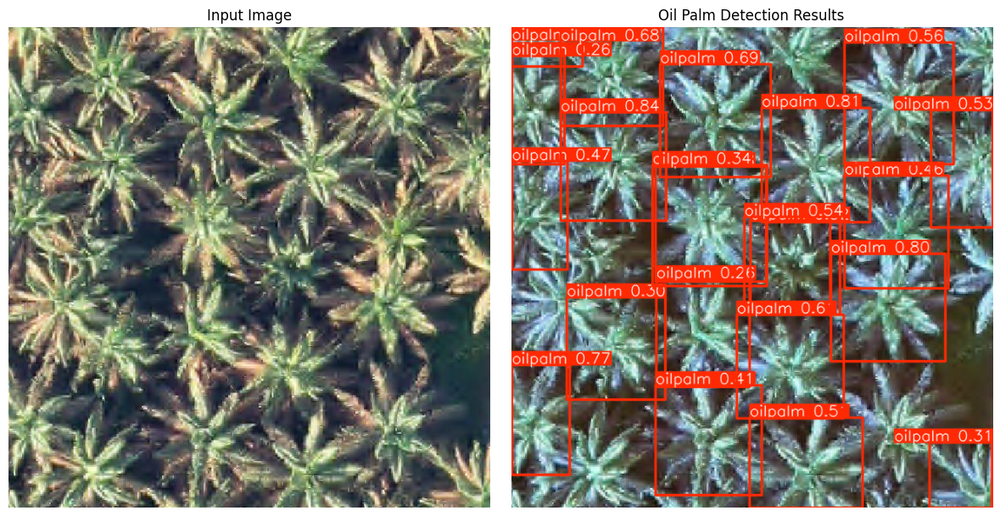

Ground Truth: 19 | Detected: 22 | TP: 17 | FP: 5 | FN: 2
----------------------------------------------------------------------

Processing image 7/10: 36_png.rf.b1f758eda3d16c5c6a1a26e55e92f2de.jpg


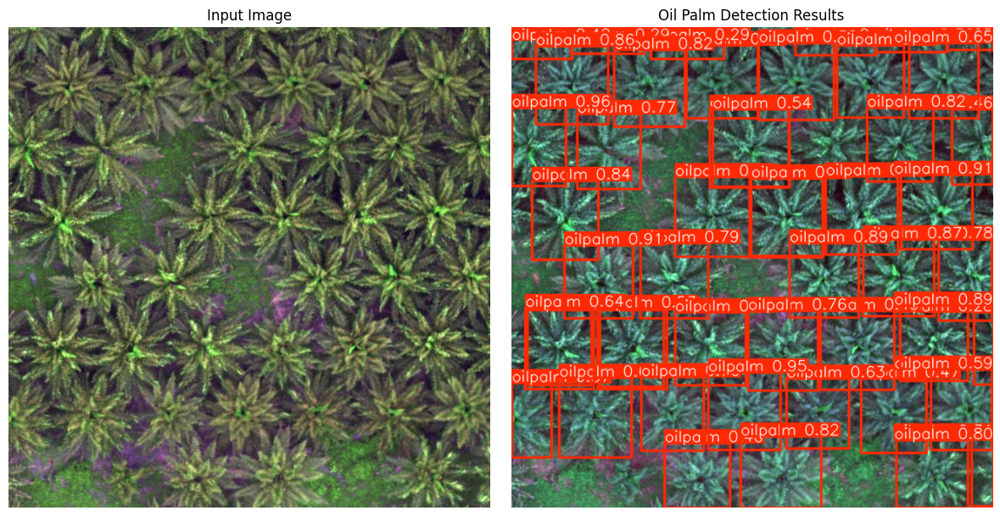

Ground Truth: 35 | Detected: 49 | TP: 38 | FP: 11 | FN: -3
----------------------------------------------------------------------

Processing image 8/10: 15_png.rf.292be4f838a90e0462060687366165ea.jpg


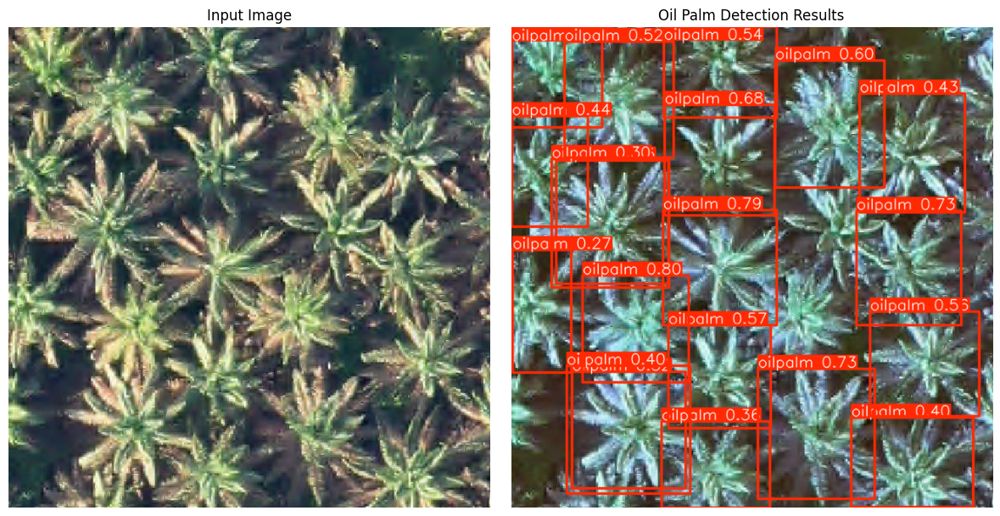

Ground Truth: 17 | Detected: 20 | TP: 17 | FP: 3 | FN: 0
----------------------------------------------------------------------

Processing image 9/10: 18_png.rf.7dcd7655ff949742951f667c533b4cef.jpg


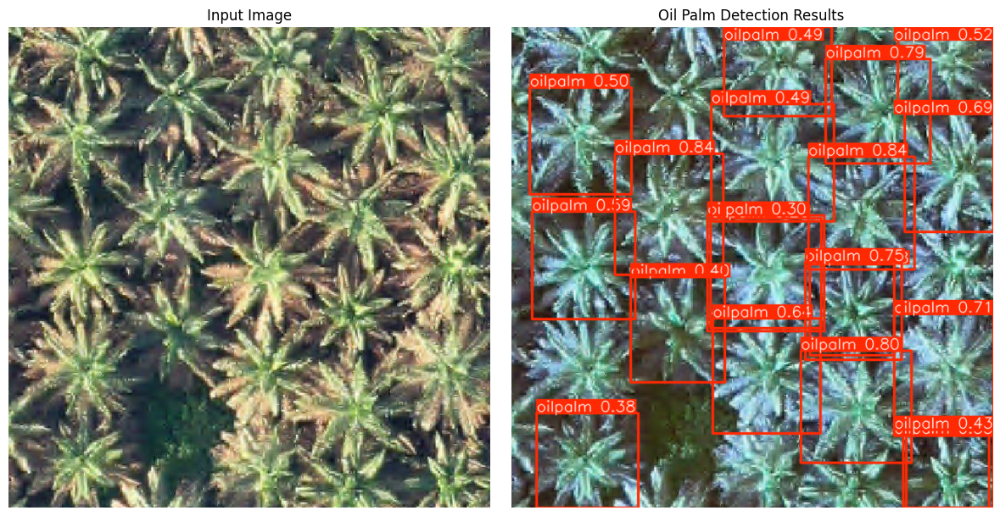

Ground Truth: 19 | Detected: 20 | TP: 17 | FP: 3 | FN: 2
----------------------------------------------------------------------

Processing image 10/10: 11_png.rf.577b365f6d0b368c80dd31d461597675.jpg


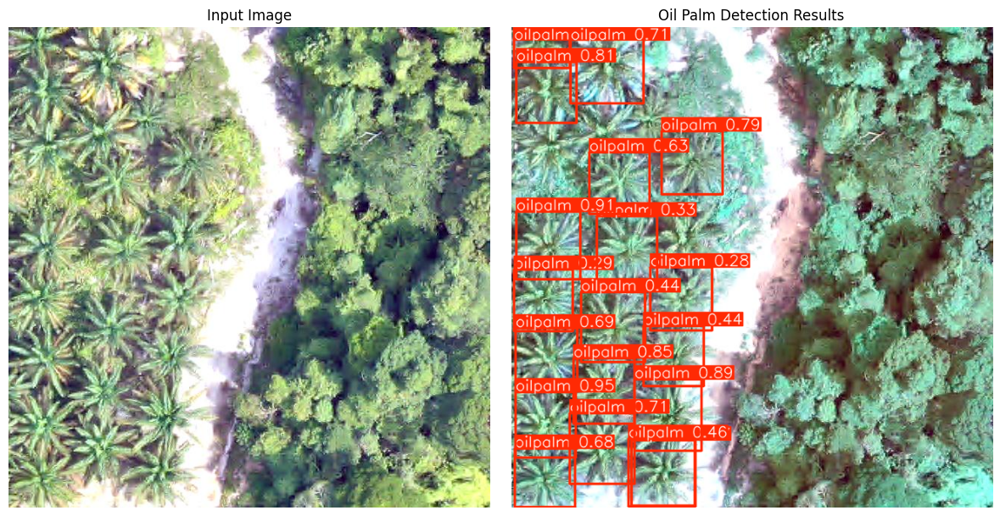

Ground Truth: 21 | Detected: 19 | TP: 18 | FP: 1 | FN: 3
----------------------------------------------------------------------


OVERALL PERFORMANCE METRICS
Total True Positives: 254
Total False Positives: 51
Total False Negatives: 2
Precision: 0.8328
Recall: 0.9922
F1-Score: 0.9055


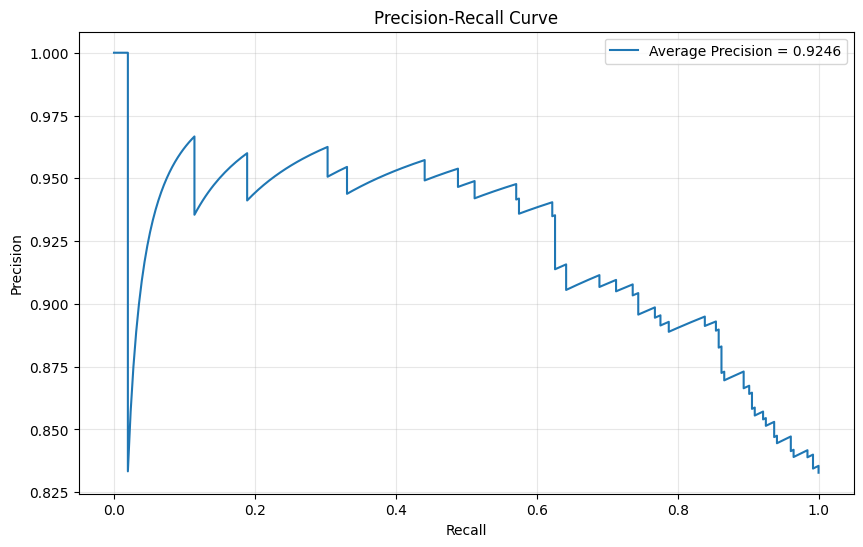

Average Precision (AP): 0.9246


In [14]:
# Calculate Intersection over Union (IoU)
def calculate_iou(box1, box2):
    """Calculates Intersection over Union (IoU) between two bounding boxes."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter_area = max(0, x2 - x1 + 1) * max(0, y2 - y1 + 1)
    box1_area = (box1[2] - box1[0] + 1) * (box1[3] - box1[1] + 1)
    box2_area = (box2[2] - box2[0] + 1) * (box2[3] - box2[1] + 1)
    union_area = box1_area + box2_area - inter_area
    iou = inter_area / union_area
    return iou

# Initialize variables for metrics calculation
total_true_positives = 0
total_false_positives = 0
total_false_negatives = 0

# Initialize lists to store true labels and predicted scores
all_true_labels = []
all_predicted_scores = []

# Apply the model to each image and calculate metrics
for idx, img_path in enumerate(validation_images, 1):
    print(f"Processing image {idx}/{len(validation_images)}: {os.path.basename(img_path)}")

    # Perform inference on the validation image
    results = model.predict(source=img_path, save=False, verbose=False)

    # Get ground truth labels for this image (assuming labels are in YOLO format)
    label_path = img_path.replace('images', 'labels').replace(os.path.splitext(img_path)[1], '.txt')
    ground_truth_boxes = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                class_id, x_center, y_center, width, height = map(float, line.strip().split())
                ground_truth_boxes.append([class_id, x_center, y_center, width, height])

    # Extract predicted boxes and confidence scores
    predicted_boxes = []
    if results[0].boxes is not None:
        for box in results[0].boxes:
            predicted_boxes.append(box.xyxy[0].tolist())  # Get bounding box coordinates

    # Match predicted boxes to ground truth boxes
    true_positives = 0
    false_positives = 0
    false_negatives = len(ground_truth_boxes)  # Initialize with all ground truths as FN

    for pred_box in predicted_boxes:
        is_matched = False
        for gt_box in ground_truth_boxes:
            # Convert normalized coordinates to pixel coordinates
            img_height, img_width = results[0].orig_shape
            gt_xmin = int((gt_box[1] - gt_box[3] / 2) * img_width)
            gt_ymin = int((gt_box[2] - gt_box[4] / 2) * img_height)
            gt_xmax = int((gt_box[1] + gt_box[3] / 2) * img_width)
            gt_ymax = int((gt_box[2] + gt_box[4] / 2) * img_height)

            iou = calculate_iou(pred_box, [gt_xmin, gt_ymin, gt_xmax, gt_ymax])

            if iou > 0.5:  # Adjust IOU threshold as needed
                true_positives += 1
                false_negatives -= 1
                is_matched = True
                break  # Stop if a match is found

        if not is_matched:
            false_positives += 1

    # Update total counts
    total_true_positives += true_positives
    total_false_positives += false_positives
    total_false_negatives += false_negatives

    # Extract true labels and predicted scores from results
    true_labels = []
    predicted_scores = []

    if results[0].boxes is not None:
        for box in results[0].boxes:
            predicted_scores.append(box.conf.item())  # Get confidence score
            true_label = 0  # Default to negative label

            for gt_box in ground_truth_boxes:
                # Convert normalized coordinates to pixel coordinates
                img_height, img_width = results[0].orig_shape
                gt_xmin = int((gt_box[1] - gt_box[3] / 2) * img_width)
                gt_ymin = int((gt_box[2] - gt_box[4] / 2) * img_height)
                gt_xmax = int((gt_box[1] + gt_box[3] / 2) * img_width)
                gt_ymax = int((gt_box[2] + gt_box[4] / 2) * img_height)

                pred_xmin, pred_ymin, pred_xmax, pred_ymax = map(int, box.xyxy[0].tolist())

                iou = calculate_iou([pred_xmin, pred_ymin, pred_xmax, pred_ymax],
                                     [gt_xmin, gt_ymin, gt_xmax, gt_ymax])

                if iou > 0.5:  # Adjust IOU threshold as needed
                    true_label = 1
                    break  # Stop if a match is found

            true_labels.append(true_label)

    all_true_labels.extend(true_labels)
    all_predicted_scores.extend(predicted_scores)

    # Load the original image
    original_image = cv2.imread(img_path)
    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    # Plot the original image and the predicted results
    plt.figure(figsize=(12, 6))

    # Original Image
    plt.subplot(1, 2, 1)
    plt.imshow(original_image)
    plt.title('Input Image')
    plt.axis('off')

    # Predicted Image with detections
    plt.subplot(1, 2, 2)
    plt.imshow(results[0].plot())
    plt.title('Oil Palm Detection Results')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    # Print per-image statistics
    print(f"Ground Truth: {len(ground_truth_boxes)} | Detected: {len(predicted_boxes)} | TP: {true_positives} | FP: {false_positives} | FN: {false_negatives}")
    print("-" * 70 + "\n")

# Calculate overall precision, recall, and F1-score
precision = total_true_positives / (total_true_positives + total_false_positives) if (total_true_positives + total_false_positives) > 0 else 0
recall = total_true_positives / (total_true_positives + total_false_negatives) if (total_true_positives + total_false_negatives) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# Print overall metrics
print("\n" + "=" * 70)
print("OVERALL PERFORMANCE METRICS")
print("=" * 70)
print(f"Total True Positives: {total_true_positives}")
print(f"Total False Positives: {total_false_positives}")
print(f"Total False Negatives: {total_false_negatives}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1_score:.4f}")

# Check if there are any positive classes and plot the Average Precision curve
if len(all_true_labels) == 0 or np.sum(all_true_labels) == 0:
    print("\n No positive class found in ground truth. Please check your validation dataset and labels.")
else:
    # Calculate precision-recall curve
    precision_curve, recall_curve, _ = precision_recall_curve(all_true_labels, all_predicted_scores)
    average_precision = average_precision_score(all_true_labels, all_predicted_scores)

    # Plot precision-recall curve
    plt.figure(figsize=(10, 6))
    plt.plot(recall_curve, precision_curve, label=f'Average Precision = {average_precision:.4f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # Print average precision
    print(f"Average Precision (AP): {average_precision:.4f}")
    print("=" * 70)

## Model Evaluation Metrics

**IoU (Intersection over Union)**

Definition: IoU measures the overlap between predicted bounding boxes and ground truth boxes. It's used to determine if a detection is correct.

Formula: IoU = Intersection Area / Union Area

Interpretation:
- IoU > 0.5: Detection is considered correct (True Positive)
- IoU < 0.5: Detection is considered incorrect (False Positive)

Example: If IoU = 0.75, it means the predicted box and ground truth box overlap by 75%.

---

**Recall (Sensitivity)**

Definition: Recall measures how well the model finds all relevant objects in the dataset. In this case, it measures how well the model detects all oil palm trees that actually exist in the image.

Formula: Recall = True Positives / (True Positives + False Negatives)

Interpretation:
- High recall value (close to 1) indicates the model can detect most oil palm trees.
- Low recall value indicates the model misses many oil palm trees.

Example: If your model's recall is 0.85, it means the model successfully detects 85% of the total oil palm trees in the image. The remaining 15% are missed (False Negatives).

---

**Precision (Positive Predictive Value)**

Definition: Precision measures how accurate the model is in identifying relevant objects. In this case, it measures how many objects predicted as oil palm trees are actually oil palm trees.

Formula: Precision = True Positives / (True Positives + False Positives)

Interpretation:
- High precision value (close to 1) indicates the model is very accurate in detecting oil palm trees with few false detections.
- Low precision value indicates the model makes many false detections, identifying other objects as oil palm trees.

Example: If your model's precision is 0.92, it means 92% of objects predicted as oil palm trees are indeed oil palm trees. The remaining 8% are false detections (False Positives).

---

**F1-Score**

Definition: F1-Score is the harmonic mean of precision and recall. It provides a balance between these two metrics.

Formula: F1-Score = 2 × (Precision × Recall) / (Precision + Recall)

Interpretation:
- High F1-Score indicates the model has good precision and recall.
- Low F1-Score indicates the model has poor precision or recall, or both.

Example: If your model's F1-Score is 0.88, it means the model has a good balance between precision and recall.

---

**Average Precision (AP)**

Definition: Average Precision summarizes the precision-recall curve. It measures the average precision across all recall levels.

Interpretation:
- High AP value (close to 1) indicates the model has high precision at most recall levels. This means the model is very accurate in detecting oil palm trees and can also find almost all oil palm trees in the image.
- Low AP value indicates the model has low precision at some recall levels.

Example: If your model's AP is 0.95, it means the model has very high precision at most recall levels. This is an indicator of excellent model performance.